# Solving a Stochastic Consumption–Saving Problem with Reinforcement Learning

**Reinforcement Learning Final Project — Fall 2026**

## Research question

> Can model-free reinforcement learning learn a near-optimal consumption–saving policy that is traditionally solved by Dynamic Programming?

This submission notebook contains the clean final pipeline:

1. Economic model and MDP formulation
2. Gymnasium environment
3. DP-Fine and DP-Matched benchmarks
4. Random and Fixed-policy baselines
5. DQN and discrete PPO implementations
6. Final 5-seed results
7. Risk-aversion robustness
8. Conclusions and limitations

**Design choice:** `Run all` recomputes the economic model, DP, baselines, figures, and robustness quickly.  
The expensive 5-seed RL training is not repeated automatically; its verified final results are embedded below, while the training implementations are preserved for reproducibility.

## 1. Economic model and MDP

The household has assets \(a_t\) and stochastic income \(y_t\).

\[
m_t = R a_t + y_t
\]

is cash on hand.

The RL state is

\[
s_t=(a_t,y_t),
\]

where

\[
y_t\in\{y_H,y_L\}=\{1.0,0.472\}
\]

and income follows

\[
P=
\begin{bmatrix}
0.9393 & 0.0607\\
0.3920 & 0.6080
\end{bmatrix}.
\]

The action is a saving share

\[
z_t\in\{0,0.05,\ldots,0.95\}.
\]

Consumption and next-period assets are

\[
c_t=(1-z_t)m_t,
\qquad
a_{t+1}=z_t m_t.
\]

The period reward is CRRA utility:

\[
u(c_t)=\frac{c_t^{1-\sigma}}{1-\sigma},
\qquad \sigma=2.
\]

The objective is

\[
\max_\pi E_\pi
\left[
\sum_{t=0}^{\infty}
\beta^t u(c_t)
\right].
\]

Therefore the economic problem is an MDP with:

- **State:** \((a_t,y_t)\)
- **Action:** saving share \(z_t\)
- **Reward:** utility of current consumption
- **Transition:** deterministic asset accumulation + stochastic income transition

In [1]:
# ============================================================
# 2. Setup and calibration
# ============================================================

import sys
import subprocess
import random
import copy
from collections import deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import gymnasium as gym
except ModuleNotFoundError:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "gymnasium"]
    )
    import gymnasium as gym

from gymnasium import spaces

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

try:
    from stable_baselines3 import PPO
    from stable_baselines3.common.monitor import Monitor
    SB3_AVAILABLE = True
except ModuleNotFoundError:
    SB3_AVAILABLE = False

R = 1.00985
BETA = 0.9703
SIGMA = 2.0

Y_HIGH = 1.0
Y_LOW = 0.472

P_INCOME = np.array([
    [0.9393, 0.0607],
    [0.3920, 0.6080]
], dtype=np.float64)

SAVING_SHARES = np.arange(
    0.0, 1.0, 0.05, dtype=np.float64
)

A_MAX = 4.5
N_ASSETS = 500

TEST_EPISODES = 2000
TEST_HORIZON = 500
TEST_SEED = 10000

print("Python:", sys.version.split()[0])
print("Gymnasium:", gym.__version__)
print("PyTorch:", torch.__version__)
print("Discrete actions:", len(SAVING_SHARES))

Python: 3.13.18
Gymnasium: 1.4.0
PyTorch: 2.11.0+cpu
Discrete actions: 20


In [2]:
# ============================================================
# 3. Gymnasium environment
# ============================================================

class ConsumptionSavingEnv(gym.Env):
    metadata = {"render_modes": []}

    def __init__(
        self,
        random_initial_state=False,
        initial_asset=1.0,
        initial_income_state=0,
        sigma=SIGMA
    ):
        super().__init__()

        self.random_initial_state = bool(random_initial_state)
        self.initial_asset = float(initial_asset)
        self.initial_income_state = int(initial_income_state)
        self.sigma = float(sigma)

        self.action_space = spaces.Discrete(
            len(SAVING_SHARES)
        )

        self.observation_space = spaces.Box(
            low=np.array([0.0, Y_LOW], dtype=np.float32),
            high=np.array([np.inf, Y_HIGH], dtype=np.float32),
            dtype=np.float32
        )

        self.asset = None
        self.income_state = None

    def _obs(self):
        income = Y_HIGH if self.income_state == 0 else Y_LOW
        return np.array([self.asset, income], dtype=np.float32)

    def _utility(self, consumption):
        if np.isclose(self.sigma, 1.0):
            return float(np.log(consumption))

        return float(
            consumption ** (1.0 - self.sigma)
            / (1.0 - self.sigma)
        )

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        options = options or {}

        if "initial_asset" in options:
            self.asset = float(options["initial_asset"])
        elif self.random_initial_state:
            self.asset = float(self.np_random.uniform(0.0, A_MAX))
        else:
            self.asset = self.initial_asset

        if "initial_income_state" in options:
            self.income_state = int(options["initial_income_state"])
        elif self.random_initial_state:
            self.income_state = int(self.np_random.integers(0, 2))
        else:
            self.income_state = self.initial_income_state

        return self._obs(), {}

    def step(self, action):
        z = float(SAVING_SHARES[int(action)])

        income = Y_HIGH if self.income_state == 0 else Y_LOW
        cash_on_hand = R * self.asset + income

        next_asset = z * cash_on_hand
        consumption = (1.0 - z) * cash_on_hand

        reward = self._utility(consumption)

        next_income_state = int(
            self.np_random.choice(
                2,
                p=P_INCOME[self.income_state]
            )
        )

        self.asset = next_asset
        self.income_state = next_income_state

        return (
            self._obs(),
            reward,
            False,
            False,
            {
                "saving_share": z,
                "consumption": consumption,
                "next_asset": next_asset
            }
        )


# Sanity check
env = ConsumptionSavingEnv()
obs, _ = env.reset(seed=42)
next_obs, reward, _, _, info = env.step(10)  # saving share = 0.50

print("Initial state:", obs)
print("Saving share:", info["saving_share"])
print("Consumption:", info["consumption"])
print("Next state:", next_obs)
print("Reward:", reward)

Initial state: [1. 1.]
Saving share: 0.5
Consumption: 1.004925
Next state: [1.004925 1.      ]
Reward: -0.9950991367514987


## 4. Dynamic Programming benchmarks

Two DP solutions are used.

### DP-Fine

The next asset is selected from a dense 500-point asset grid.  
This approximates the underlying economic optimum.

### DP-Matched

The planner is restricted to the **same 20 saving-share actions** used by DQN and PPO.

Hence DP-Matched is the fair oracle benchmark for the RL algorithms, while the difference between DP-Fine and DP-Matched measures the cost of action discretization.

In [3]:
# ============================================================
# 4A. DP solvers
# ============================================================

def crra_utility(c, sigma=SIGMA):
    c = np.asarray(c, dtype=np.float64)

    if np.isclose(sigma, 1.0):
        return np.log(c)

    return c ** (1.0 - sigma) / (1.0 - sigma)


def solve_dp_matched(
    sigma=SIGMA,
    tolerance=1e-10,
    max_iterations=5000
):
    asset_grid = np.linspace(0.0, A_MAX, N_ASSETS)

    V = np.zeros((N_ASSETS, 2), dtype=np.float64)
    policy_share = np.zeros_like(V)

    for iteration in range(max_iterations):
        V_new = np.empty_like(V)

        for income_state, income in [(0, Y_HIGH), (1, Y_LOW)]:
            cash = R * asset_grid + income

            Q = np.full(
                (N_ASSETS, len(SAVING_SHARES)),
                -np.inf,
                dtype=np.float64
            )

            for j, z in enumerate(SAVING_SHARES):
                next_asset = z * cash
                consumption = (1.0 - z) * cash

                feasible = (
                    (consumption > 1e-12)
                    &
                    (next_asset <= A_MAX)
                )

                V_high = np.interp(
                    next_asset, asset_grid, V[:, 0]
                )
                V_low = np.interp(
                    next_asset, asset_grid, V[:, 1]
                )

                expected_future = (
                    P_INCOME[income_state, 0] * V_high
                    +
                    P_INCOME[income_state, 1] * V_low
                )

                q = (
                    crra_utility(consumption, sigma)
                    +
                    BETA * expected_future
                )

                q[~feasible] = -np.inf
                Q[:, j] = q

            best_idx = np.argmax(Q, axis=1)

            V_new[:, income_state] = (
                Q[np.arange(N_ASSETS), best_idx]
            )

            policy_share[:, income_state] = (
                SAVING_SHARES[best_idx]
            )

        diff = np.max(np.abs(V_new - V))
        V = V_new

        if diff < tolerance:
            break

    return asset_grid, V, policy_share


def solve_dp_fine(
    sigma=SIGMA,
    tolerance=1e-10,
    max_iterations=5000
):
    asset_grid = np.linspace(0.0, A_MAX, N_ASSETS)

    V = np.zeros((N_ASSETS, 2), dtype=np.float64)
    policy_asset = np.zeros_like(V)

    for iteration in range(max_iterations):
        V_new = np.empty_like(V)

        for income_state, income in [(0, Y_HIGH), (1, Y_LOW)]:
            cash = R * asset_grid + income

            consumption = (
                cash[:, None]
                -
                asset_grid[None, :]
            )

            feasible = consumption > 1e-12

            utility = np.full(
                consumption.shape,
                -np.inf,
                dtype=np.float64
            )

            utility[feasible] = crra_utility(
                consumption[feasible],
                sigma
            )

            expected_future = (
                P_INCOME[income_state, 0] * V[:, 0]
                +
                P_INCOME[income_state, 1] * V[:, 1]
            )

            Q = (
                utility
                +
                BETA * expected_future[None, :]
            )

            best_idx = np.argmax(Q, axis=1)

            V_new[:, income_state] = (
                Q[np.arange(N_ASSETS), best_idx]
            )

            policy_asset[:, income_state] = (
                asset_grid[best_idx]
            )

        diff = np.max(np.abs(V_new - V))
        V = V_new

        if diff < tolerance:
            break

    return asset_grid, V, policy_asset


asset_grid_m, V_dp_matched, policy_share_matched = (
    solve_dp_matched()
)

asset_grid_f, V_dp_fine, policy_asset_fine = (
    solve_dp_fine()
)

dp_matched_value = np.interp(
    1.0, asset_grid_m, V_dp_matched[:, 0]
)

dp_fine_value = np.interp(
    1.0, asset_grid_f, V_dp_fine[:, 0]
)

print("DP-Matched Bellman value:", dp_matched_value)
print("DP-Fine Bellman value:", dp_fine_value)
print("Fine-action gain:", dp_fine_value - dp_matched_value)

DP-Matched Bellman value: -36.23960733972141
DP-Fine Bellman value: -36.217538375334115
Fine-action gain: 0.022068964387294443


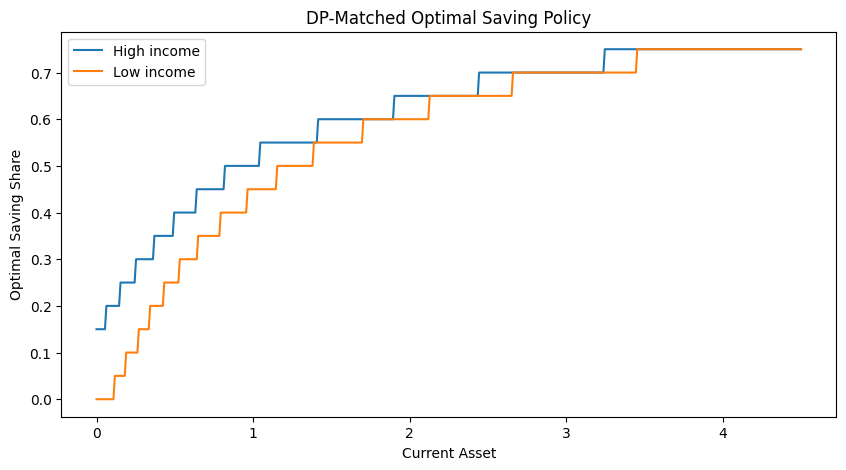

At asset ≈ 1.001002004008016
High-income optimal saving: 0.5
Low-income optimal saving: 0.45


In [4]:
# ============================================================
# 4B. DP policy figure
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    asset_grid_m,
    policy_share_matched[:, 0],
    label="High income"
)

plt.plot(
    asset_grid_m,
    policy_share_matched[:, 1],
    label="Low income"
)

plt.xlabel("Current Asset")
plt.ylabel("Optimal Saving Share")
plt.title("DP-Matched Optimal Saving Policy")
plt.legend()
plt.show()

idx_a1 = np.argmin(
    np.abs(asset_grid_m - 1.0)
)

print("At asset ≈", asset_grid_m[idx_a1])
print(
    "High-income optimal saving:",
    policy_share_matched[idx_a1, 0]
)
print(
    "Low-income optimal saving:",
    policy_share_matched[idx_a1, 1]
)

## 5. Baselines and common evaluation

All policies are evaluated from

\[
(a_0,y_0)=(1,H)
\]

using the same 2,000 Monte Carlo income paths over 500 quarters.

The main metric is discounted lifetime utility.

In [5]:
# ============================================================
# 5A. Vectorized evaluation
# ============================================================

def summarize_returns(returns):
    returns = np.asarray(returns, dtype=np.float64)

    mean = returns.mean()
    std = returns.std(ddof=1)
    se = std / np.sqrt(len(returns))
    ci = 1.96 * se

    return {
        "mean_utility": mean,
        "std_utility": std,
        "ci_lower": mean - ci,
        "ci_upper": mean + ci
    }


def simulate_saving_policy(
    action_function,
    n_episodes=TEST_EPISODES,
    horizon=TEST_HORIZON,
    seed=TEST_SEED,
    sigma=SIGMA
):
    rng = np.random.default_rng(seed)

    assets = np.ones(n_episodes)
    income_states = np.zeros(n_episodes, dtype=int)

    returns = np.zeros(n_episodes)
    discount = 1.0

    for _ in range(horizon):
        incomes = np.where(
            income_states == 0,
            Y_HIGH,
            Y_LOW
        )

        z = action_function(
            assets,
            income_states,
            incomes
        )

        cash = R * assets + incomes
        consumption = (1.0 - z) * cash

        returns += (
            discount
            * crra_utility(consumption, sigma)
        )

        assets = z * cash

        p_low = np.where(
            income_states == 0,
            P_INCOME[0, 1],
            P_INCOME[1, 1]
        )

        income_states = (
            rng.random(n_episodes) < p_low
        ).astype(int)

        discount *= BETA

    return summarize_returns(returns)


def dp_matched_action(
    assets,
    income_states,
    incomes
):
    idx = np.clip(
        np.searchsorted(asset_grid_m, assets),
        1,
        len(asset_grid_m) - 1
    )

    left = asset_grid_m[idx - 1]
    right = asset_grid_m[idx]

    nearest_idx = np.where(
        np.abs(assets - right) < np.abs(assets - left),
        idx,
        idx - 1
    )

    return policy_share_matched[
        nearest_idx,
        income_states
    ]


dp_mc = simulate_saving_policy(
    dp_matched_action
)

print("DP-Matched Monte Carlo:", dp_mc)

DP-Matched Monte Carlo: {'mean_utility': np.float64(-36.25482128180089), 'std_utility': np.float64(1.9429592265372282), 'ci_lower': np.float64(-36.33997522439863), 'ci_upper': np.float64(-36.16966733920316)}


Best fixed policy


,saving_share,mean_utility,ci_lower,ci_upper
10,0.5,-36.745202,-36.839627,-36.650778


Random policy: {'mean_utility': np.float64(-78.1141335034981), 'std_utility': np.float64(12.051240771466716), 'ci_lower': np.float64(-78.64230241763114), 'ci_upper': np.float64(-77.58596458936505)}


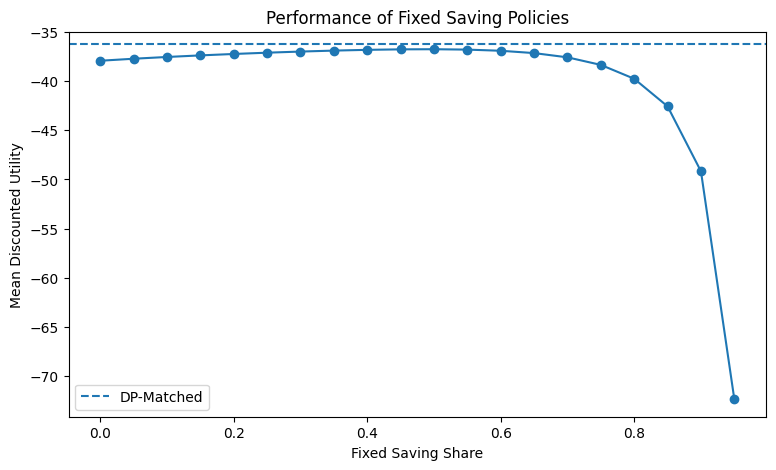

In [6]:
# ============================================================
# 5B. Fixed-policy sweep + random baseline
# ============================================================

fixed_rows = []

for z in SAVING_SHARES:
    result = simulate_saving_policy(
        lambda assets, income_states, incomes, z=z:
            np.full(len(assets), z)
    )

    fixed_rows.append({
        "saving_share": z,
        "mean_utility": result["mean_utility"],
        "ci_lower": result["ci_lower"],
        "ci_upper": result["ci_upper"]
    })

fixed_table = pd.DataFrame(fixed_rows)

best_fixed = fixed_table.loc[
    fixed_table["mean_utility"].idxmax()
]

print("Best fixed policy")
display(best_fixed.to_frame().T)


def evaluate_random_policy():
    rng = np.random.default_rng(TEST_SEED)

    assets = np.ones(TEST_EPISODES)
    income_states = np.zeros(TEST_EPISODES, dtype=int)

    returns = np.zeros(TEST_EPISODES)
    discount = 1.0

    for _ in range(TEST_HORIZON):
        incomes = np.where(
            income_states == 0,
            Y_HIGH,
            Y_LOW
        )

        cash = R * assets + incomes

        action_idx = rng.integers(
            0,
            len(SAVING_SHARES),
            size=TEST_EPISODES
        )

        z = SAVING_SHARES[action_idx]

        consumption = (1.0 - z) * cash

        returns += (
            discount * crra_utility(consumption)
        )

        assets = z * cash

        p_low = np.where(
            income_states == 0,
            P_INCOME[0, 1],
            P_INCOME[1, 1]
        )

        income_states = (
            rng.random(TEST_EPISODES) < p_low
        ).astype(int)

        discount *= BETA

    return summarize_returns(returns)


random_result = evaluate_random_policy()

print("Random policy:", random_result)


plt.figure(figsize=(9, 5))

plt.plot(
    fixed_table["saving_share"],
    fixed_table["mean_utility"],
    marker="o"
)

plt.axhline(
    dp_mc["mean_utility"],
    linestyle="--",
    label="DP-Matched"
)

plt.xlabel("Fixed Saving Share")
plt.ylabel("Mean Discounted Utility")
plt.title("Performance of Fixed Saving Policies")
plt.legend()
plt.show()

## 6. RL algorithms

### DQN

DQN learns a neural approximation to \(Q(s,a)\) using:

- replay buffer,
- target network,
- \(\epsilon\)-greedy exploration,
- Bellman TD targets.

The final experiment uses validation-based checkpoint selection because policy quality was not monotone in training time.

### PPO

For the final controlled comparison, PPO uses the **same 20 discrete actions** as DQN and DP-Matched.

The code below preserves the main model implementation. The expensive 5-seed training is not automatically executed in this clean notebook.

In [7]:
# ============================================================
# 6A. DQN model components
# ============================================================

def normalize_state(state):
    state = np.asarray(
        state,
        dtype=np.float32
    ).copy()

    state[..., 0] /= A_MAX

    return state


class ReplayBuffer:
    def __init__(self, capacity=100_000):
        self.buffer = deque(maxlen=capacity)

    def put(self, state, action, reward, next_state):
        self.buffer.append(
            (
                normalize_state(state),
                int(action),
                float(reward),
                normalize_state(next_state)
            )
        )

    def sample(self, batch_size):
        batch = random.sample(
            self.buffer,
            batch_size
        )

        states, actions, rewards, next_states = zip(*batch)

        return (
            torch.tensor(np.asarray(states), dtype=torch.float32),
            torch.tensor(actions, dtype=torch.long),
            torch.tensor(rewards, dtype=torch.float32),
            torch.tensor(np.asarray(next_states), dtype=torch.float32)
        )

    def __len__(self):
        return len(self.buffer)


class QNetwork(nn.Module):
    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(2, 64)
        self.fc2 = nn.Linear(64, 64)
        self.fc3 = nn.Linear(
            64,
            len(SAVING_SHARES)
        )

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))

        return self.fc3(x)


def dqn_td_target(
    rewards,
    next_states,
    target_q
):
    with torch.no_grad():
        max_next_q = (
            target_q(next_states)
            .max(dim=1)
            .values
        )

        return (
            rewards
            +
            BETA * max_next_q
        )


print("DQN components loaded.")

DQN components loaded.


In [8]:
# ============================================================
# 6B. Discrete PPO specification
# ============================================================

class PPOObservationWrapper(gym.ObservationWrapper):
    def __init__(self, env):
        super().__init__(env)

        self.observation_space = spaces.Box(
            low=np.array(
                [0.0, Y_LOW],
                dtype=np.float32
            ),
            high=np.array(
                [np.inf, Y_HIGH],
                dtype=np.float32
            ),
            dtype=np.float32
        )

    def observation(self, observation):
        obs = np.asarray(
            observation,
            dtype=np.float32
        ).copy()

        obs[0] /= A_MAX

        return obs


def make_ppo_env():
    env = ConsumptionSavingEnv(
        random_initial_state=True
    )

    env = PPOObservationWrapper(env)

    env = gym.wrappers.TimeLimit(
        env,
        max_episode_steps=200
    )

    if SB3_AVAILABLE:
        env = Monitor(env)

    return env


PPO_CONFIG = {
    "learning_rate": 3e-4,
    "n_steps": 2048,
    "batch_size": 64,
    "gamma": BETA,
    "gae_lambda": 0.95,
    "clip_range": 0.2,
    "ent_coef": 0.0
}

print("PPO configuration:", PPO_CONFIG)

PPO configuration: {'learning_rate': 0.0003, 'n_steps': 2048, 'batch_size': 64, 'gamma': 0.9703, 'gae_lambda': 0.95, 'clip_range': 0.2, 'ent_coef': 0.0}


## 7. Final five-seed experiment

Training seeds:

\[
\{0,1,2,3,4\}.
\]

For every seed, the best validation checkpoint was selected and then evaluated using the same independent test income paths.

For DQN and PPO, the confidence intervals in the final table are **t-based intervals across the five training seeds**. This measures training-seed variability.

The verified results below come from the completed final multi-seed experiment.

In [9]:
# ============================================================
# 7A. Verified seed-level final results
# ============================================================

seed_results = pd.DataFrame(
    [
        ["DQN", 0, 15000, -36.62476375359431, 0.06925, 0.152, 0.614, 0.858, 1.0203952432089824],
        ["DQN", 1, 75000, -36.52610135582198, 0.04235, 0.402, 0.830, 0.939, 0.7482593057416720],
        ["DQN", 2, 30000, -36.39916546399537, 0.05685, 0.219, 0.648, 0.996, 0.3981378947437664],
        ["DQN", 3, 90000, -36.49452906885983, 0.05050, 0.301, 0.722, 0.971, 0.6611749240073239],
        ["DQN", 4, 60000, -36.46873513384603, 0.04360, 0.393, 0.779, 0.956, 0.5900287037203356],
        ["PPO", 0, 100000, -36.726899302114845, 0.12375, 0.096, 0.285, 0.463, 1.3021110120626123],
        ["PPO", 1, 30000, -36.73167378429328, 0.23220, 0.043, 0.119, 0.201, 1.3152802458627821],
        ["PPO", 2, 10000, -36.75828128930705, 0.08995, 0.158, 0.473, 0.836, 1.3886704987258636],
        ["PPO", 3, 20000, -36.75828128930705, 0.20520, 0.041, 0.127, 0.233, 1.3886704987258636],
        ["PPO", 4, 20000, -36.88557688580925, 0.27310, 0.030, 0.091, 0.154, 1.7397840665263065],
    ],
    columns=[
        "Algorithm",
        "Training Seed",
        "Best Step",
        "Test Mean Utility",
        "Policy MAE",
        "Exact Agreement",
        "Within 5pp",
        "Within 10pp",
        "CEV Loss vs DP (%)"
    ]
)

final_summary = pd.DataFrame(
    [
        ["Fixed 50%", -36.74520228639539, np.nan, -36.839626826673964, -36.650777746116816, np.nan, np.nan, np.nan, np.nan, 1.3525952887282644],
        ["DP-Matched", -36.25482128180089, np.nan, -36.33997522439863, -36.16966733920316, 0.0, 1.0, 1.0, 1.0, 0.0],
        ["DQN", -36.50265895522350, 0.08274501702024054, -36.605400463888294, -36.39991744655871, 0.05251, 0.2934, 0.7186, 0.9440, 0.6835992142844161],
        ["PPO", -36.77214251016629, 0.06506975125489735, -36.85293727767157, -36.69134774266101, 0.18484, 0.0736, 0.2190, 0.3774, 1.4269032643806856],
    ],
    columns=[
        "Model",
        "Mean Utility",
        "Seed SD",
        "95% CI Lower",
        "95% CI Upper",
        "Mean Policy MAE",
        "Mean Exact",
        "Mean Within 5pp",
        "Mean Within 10pp",
        "Mean CEV Loss vs DP (%)"
    ]
)

display(seed_results)
display(final_summary)

,Algorithm,Training Seed,Best Step,Test Mean Utility,Policy MAE,Exact Agreement,Within 5pp,Within 10pp,CEV Loss vs DP (%)
0,DQN,0,15000,-36.624764,0.06925,0.152,0.614,0.858,1.020395
1,DQN,1,75000,-36.526101,0.04235,0.402,0.830,0.939,0.748259
2,DQN,2,30000,-36.399165,0.05685,0.219,0.648,0.996,0.398138
3,DQN,3,90000,-36.494529,0.05050,0.301,0.722,0.971,0.661175
4,DQN,4,60000,-36.468735,0.04360,0.393,0.779,0.956,0.590029
5,PPO,0,100000,-36.726899,0.12375,0.096,0.285,0.463,1.302111
6,PPO,1,30000,-36.731674,0.23220,0.043,0.119,0.201,1.315280
7,PPO,2,10000,-36.758281,0.08995,0.158,0.473,0.836,1.388670
8,PPO,3,20000,-36.758281,0.20520,0.041,0.127,0.233,1.388670
9,PPO,4,20000,-36.885577,0.27310,0.030,0.091,0.154,1.739784


,Model,Mean Utility,Seed SD,95% CI Lower,95% CI Upper,Mean Policy MAE,Mean Exact,Mean Within 5pp,Mean Within 10pp,Mean CEV Loss vs DP (%)
0,Fixed 50%,-36.745202,NaN,-36.839627,-36.650778,NaN,NaN,NaN,NaN,1.352595
1,DP-Matched,-36.254821,NaN,-36.339975,-36.169667,0.00000,1.0000,1.0000,1.0000,0.000000
2,DQN,-36.502659,0.082745,-36.605400,-36.399917,0.05251,0.2934,0.7186,0.9440,0.683599
3,PPO,-36.772143,0.065070,-36.852937,-36.691348,0.18484,0.0736,0.2190,0.3774,1.426903


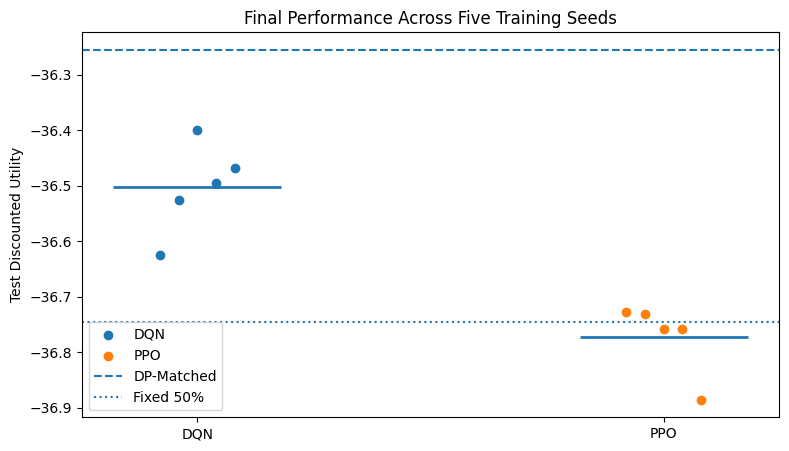

Policy-approximation summary


,Model,Mean Policy MAE,Mean Exact,Mean Within 5pp,Mean Within 10pp,Mean CEV Loss vs DP (%)
2,DQN,0.05251,0.2934,0.7186,0.9440,0.683599
3,PPO,0.18484,0.0736,0.2190,0.3774,1.426903


Best checkpoint by training seed


,Algorithm,Training Seed,Best Step
0,DQN,0,15000
1,DQN,1,75000
2,DQN,2,30000
3,DQN,3,90000
4,DQN,4,60000
5,PPO,0,100000
6,PPO,1,30000
7,PPO,2,10000
8,PPO,3,20000
9,PPO,4,20000


In [10]:
# ============================================================
# 7B. Final figures
# ============================================================

plt.figure(figsize=(9, 5))

for i, algorithm in enumerate(["DQN", "PPO"]):
    vals = seed_results.loc[
        seed_results["Algorithm"] == algorithm,
        "Test Mean Utility"
    ].values

    offsets = np.linspace(-0.08, 0.08, len(vals))

    plt.scatter(
        np.full(len(vals), i) + offsets,
        vals,
        label=algorithm
    )

    plt.hlines(
        vals.mean(),
        i - 0.18,
        i + 0.18,
        linewidth=2
    )

dp_mean = final_summary.loc[
    final_summary["Model"] == "DP-Matched",
    "Mean Utility"
].iloc[0]

fixed_mean = final_summary.loc[
    final_summary["Model"] == "Fixed 50%",
    "Mean Utility"
].iloc[0]

plt.axhline(
    dp_mean,
    linestyle="--",
    label="DP-Matched"
)

plt.axhline(
    fixed_mean,
    linestyle=":",
    label="Fixed 50%"
)

plt.xticks([0, 1], ["DQN", "PPO"])
plt.ylabel("Test Discounted Utility")
plt.title("Final Performance Across Five Training Seeds")
plt.legend()
plt.show()


print("Policy-approximation summary")

display(
    final_summary.loc[
        final_summary["Model"].isin(["DQN", "PPO"]),
        [
            "Model",
            "Mean Policy MAE",
            "Mean Exact",
            "Mean Within 5pp",
            "Mean Within 10pp",
            "Mean CEV Loss vs DP (%)"
        ]
    ]
)


print("Best checkpoint by training seed")

display(
    seed_results[
        ["Algorithm", "Training Seed", "Best Step"]
    ]
    .sort_values(
        ["Algorithm", "Training Seed"]
    )
)

### Main empirical result

\[
\boxed{
DP\text{-Matched} > DQN > Fixed \approx PPO
}
\]

Across five training seeds:

- **DP-Matched:** \(-36.255\)
- **DQN:** \(-36.503\)
- **Fixed 50%:** \(-36.745\)
- **PPO:** \(-36.772\)

DQN's mean consumption-equivalent welfare loss relative to DP is only about

\[
0.68\%.
\]

DQN chooses a saving share within 10 percentage points of the DP optimum in about

\[
94.4\%
\]

of grid states.

The best DQN checkpoint varies from 15k to 90k across seeds, showing that more training is not automatically better and that validation-based checkpoint selection is economically meaningful.

## 8. Economic robustness: CRRA curvature / risk aversion

We vary

\[
\sigma\in\{1.5,2.0,3.0\}
\]

while holding the income process, return, and discount factor fixed.

Because changing \(\sigma\) changes the scale of CRRA utility, value-function levels are **not compared across different \(\sigma\)**.

Instead we compare optimal saving behavior and long-run economic outcomes.

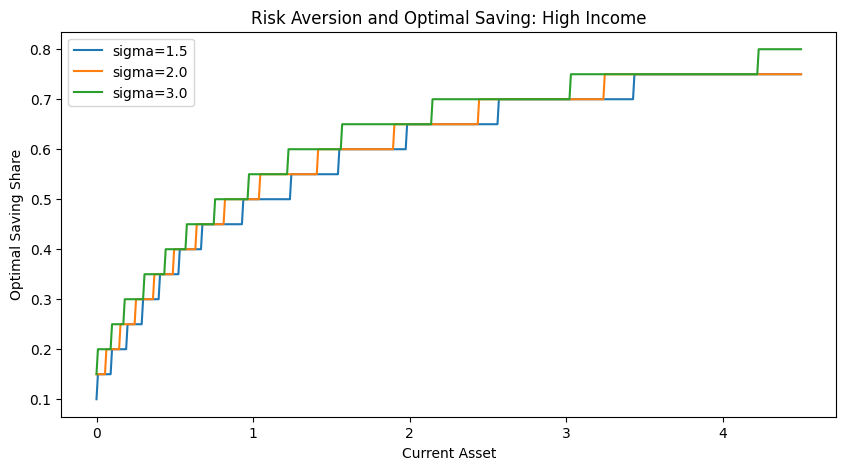

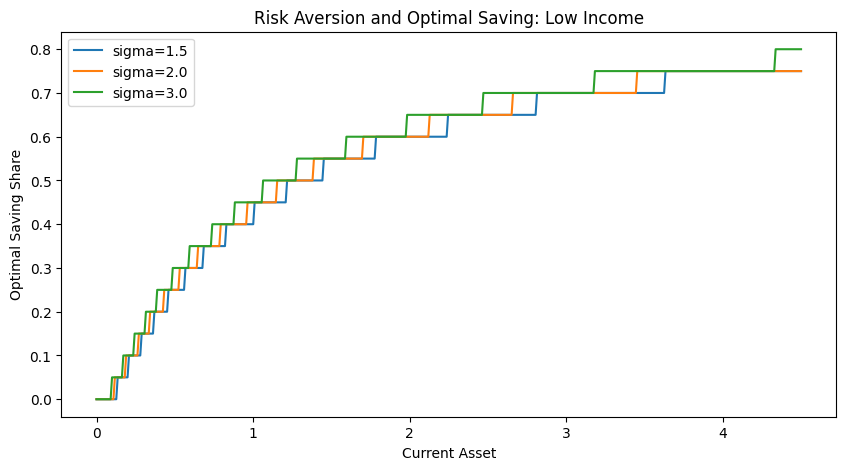

In [11]:
# ============================================================
# 8A. Comparative statics
# ============================================================

SIGMA_GRID = [1.5, 2.0, 3.0]

sigma_solutions = {}

for sigma in SIGMA_GRID:
    grid, V, policy = solve_dp_matched(
        sigma=sigma
    )

    sigma_solutions[sigma] = {
        "asset_grid": grid,
        "policy": policy
    }


plt.figure(figsize=(10, 5))

for sigma in SIGMA_GRID:
    plt.plot(
        sigma_solutions[sigma]["asset_grid"],
        sigma_solutions[sigma]["policy"][:, 0],
        label=f"sigma={sigma}"
    )

plt.xlabel("Current Asset")
plt.ylabel("Optimal Saving Share")
plt.title("Risk Aversion and Optimal Saving: High Income")
plt.legend()
plt.show()


plt.figure(figsize=(10, 5))

for sigma in SIGMA_GRID:
    plt.plot(
        sigma_solutions[sigma]["asset_grid"],
        sigma_solutions[sigma]["policy"][:, 1],
        label=f"sigma={sigma}"
    )

plt.xlabel("Current Asset")
plt.ylabel("Optimal Saving Share")
plt.title("Risk Aversion and Optimal Saving: Low Income")
plt.legend()
plt.show()

,sigma,"Saving Share | High, a≈1","Saving Share | Low, a≈1",Mean Asset,Mean Saving Share,Mean Consumption
0,1.5,0.50,0.40,0.514495,0.330439,0.934139
1,2.0,0.50,0.45,0.771886,0.424712,0.936680
2,3.0,0.55,0.45,1.146777,0.521136,0.940383


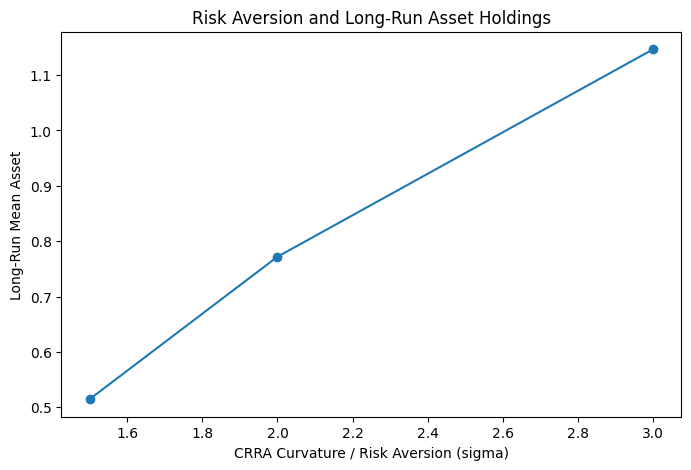

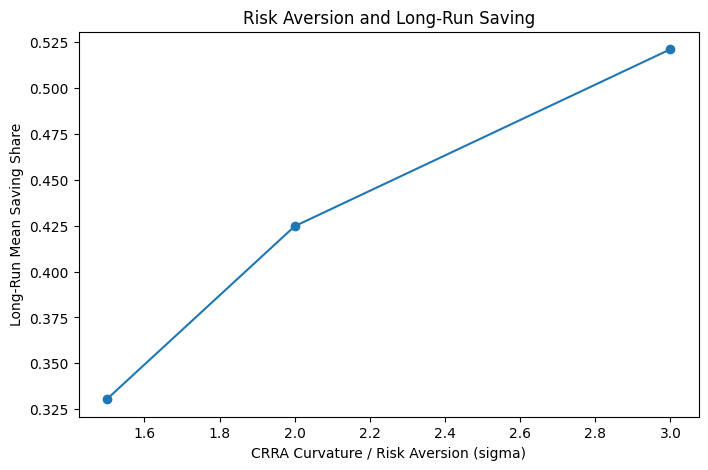

In [12]:
# ============================================================
# 8B. Long-run economic behavior
# ============================================================

def nearest_policy_action(
    assets,
    income_states,
    asset_grid,
    policy_share
):
    idx = np.clip(
        np.searchsorted(asset_grid, assets),
        1,
        len(asset_grid) - 1
    )

    left = asset_grid[idx - 1]
    right = asset_grid[idx]

    nearest_idx = np.where(
        np.abs(assets - right) < np.abs(assets - left),
        idx,
        idx - 1
    )

    return policy_share[
        nearest_idx,
        income_states
    ]


def simulate_long_run(
    asset_grid,
    policy_share,
    n_agents=5000,
    horizon=1000,
    burn_in=300,
    seed=20261102
):
    rng = np.random.default_rng(seed)

    assets = np.ones(n_agents)
    income_states = np.zeros(n_agents, dtype=int)

    asset_sum = 0.0
    saving_sum = 0.0
    consumption_sum = 0.0
    observations = 0

    for t in range(horizon):
        incomes = np.where(
            income_states == 0,
            Y_HIGH,
            Y_LOW
        )

        z = nearest_policy_action(
            assets,
            income_states,
            asset_grid,
            policy_share
        )

        cash = R * assets + incomes
        consumption = (1.0 - z) * cash
        next_assets = z * cash

        if t >= burn_in:
            asset_sum += assets.sum()
            saving_sum += z.sum()
            consumption_sum += consumption.sum()
            observations += n_agents

        p_low = np.where(
            income_states == 0,
            P_INCOME[0, 1],
            P_INCOME[1, 1]
        )

        income_states = (
            rng.random(n_agents) < p_low
        ).astype(int)

        assets = next_assets

    return {
        "Mean Asset": asset_sum / observations,
        "Mean Saving Share": saving_sum / observations,
        "Mean Consumption": consumption_sum / observations
    }


robustness_rows = []

for sigma in SIGMA_GRID:
    grid = sigma_solutions[sigma]["asset_grid"]
    policy = sigma_solutions[sigma]["policy"]

    idx = np.argmin(np.abs(grid - 1.0))

    long_run = simulate_long_run(
        grid,
        policy
    )

    robustness_rows.append({
        "sigma": sigma,
        "Saving Share | High, a≈1": policy[idx, 0],
        "Saving Share | Low, a≈1": policy[idx, 1],
        **long_run
    })

robustness_table = pd.DataFrame(
    robustness_rows
)

display(robustness_table)


plt.figure(figsize=(8, 5))

plt.plot(
    robustness_table["sigma"],
    robustness_table["Mean Asset"],
    marker="o"
)

plt.xlabel("CRRA Curvature / Risk Aversion (sigma)")
plt.ylabel("Long-Run Mean Asset")
plt.title("Risk Aversion and Long-Run Asset Holdings")
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(
    robustness_table["sigma"],
    robustness_table["Mean Saving Share"],
    marker="o"
)

plt.xlabel("CRRA Curvature / Risk Aversion (sigma)")
plt.ylabel("Long-Run Mean Saving Share")
plt.title("Risk Aversion and Long-Run Saving")
plt.show()

## 9. Conclusions

1. **DP provides the oracle benchmark.**  
   DP-Fine and DP-Matched are close, so the 5%-point action grid creates only a small loss.

2. **DQN learns a strong state-dependent policy.**  
   It consistently outperforms the simple fixed-saving rule and approaches DP-Matched.

3. **Training stability matters.**  
   The best checkpoint differs substantially across training seeds.

4. **PPO performs worse in this environment.**  
   In the final controlled discrete-action comparison, PPO does not outperform the fixed-saving baseline and approximates the DP policy much less accurately than DQN.

5. **The economic comparative statics are sensible.**  
   Higher CRRA curvature/risk aversion is associated with stronger precautionary saving and greater long-run asset accumulation.

### Main interpretation

The project does **not** claim that RL dominates DP in a small model where the transition process is known.

Instead, it shows that a **model-free DQN can learn a near-optimal dynamic economic policy without directly solving the Bellman equation**.

That is the main motivation for using RL in larger economic environments where exact DP becomes difficult.

## 10. Reproducibility

### Fast `Run all`

Recomputes:

- environment sanity check,
- DP-Fine,
- DP-Matched,
- fixed/random baselines,
- final tables and figures,
- risk-aversion robustness.

### Full RL retraining

The final training experiment used:

- training seeds: \(\{0,1,2,3,4\}\),
- DQN: up to 100,000 environment steps per seed,
- PPO: up to 100,000 timesteps per seed,
- validation checkpoint selection,
- common independent test income paths.

Full multi-seed retraining is intentionally excluded from automatic execution because it is computationally expensive. The research log and saved model files should be retained alongside this clean notebook in the GitHub repository.